# Dijkstra

Calculating shortest path from 0 to 4...
Path found: 0 -> 2 -> 5 -> 4
Total Cost: 20


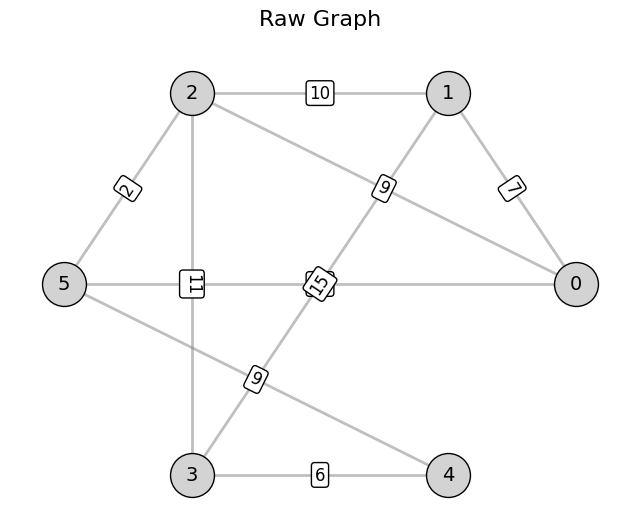

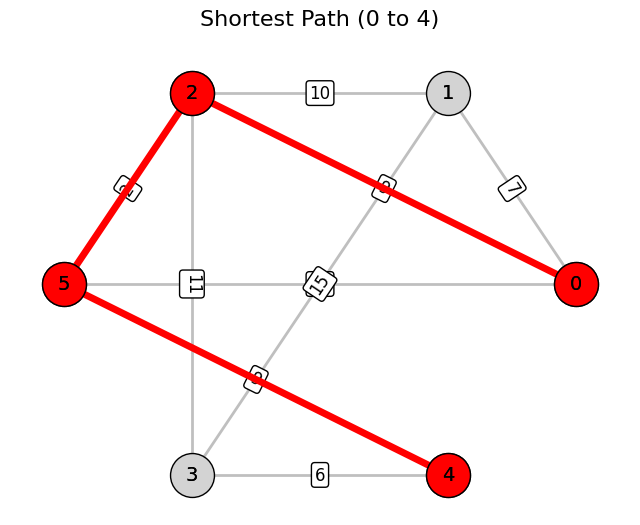

In [6]:
import networkx as nx
import matplotlib.pyplot as plt

# --- Your Dijkstra Algorithm ---

def get_min_dist(dist, visited, v):
    min_dist = float('inf')
    min_index = -1
    for i in range(v): 
        if dist[i] < min_dist and not visited[i]:
            min_dist = dist[i]
            min_index = i
    return min_index

def dijkstra(graph, src):
    v = len(graph)
    distances = [float('inf')] * v
    distances[src] = 0
    visited = [False] * v
    previous = [-1] * v

    for _ in range(v):
        u = get_min_dist(distances, visited, v)
        if u == -1: 
            break 
        visited[u] = True

        for neighbor in range(v):
            edge_weight = graph[u][neighbor]
            if edge_weight > 0 and not visited[neighbor]:
                new_distance = distances[u] + edge_weight
                if new_distance < distances[neighbor]:
                    distances[neighbor] = new_distance
                    previous[neighbor] = u

    return distances, previous

def get_shortest_path(previous, src, dest):
    path = []
    current = dest
    while current != -1:
        path.append(current)
        current = previous[current]
    path.reverse()

    if len(path) > 0 and path[0] == src:
        return path
    else:
        return []

# --- Plotting Logic ---

def plot_graphs(graph_matrix, shortest_path, src, dest):
    # 1. Initialize the Graph
    G = nx.Graph()
    v = len(graph_matrix)
    
    # Add edges from adjacency matrix
    for i in range(v):
        for j in range(i + 1, v):
            weight = graph_matrix[i][j]
            if weight > 0:
                G.add_edge(i, j, weight=weight)

    # Set layout for consistent node positioning
    pos = nx.circular_layout(G) 

    # --- IMAGE 1: Raw Graph ---
    plt.figure(1, figsize=(8, 6))
    plt.title("Raw Graph", fontsize=16, pad=20)
    
    # Draw base graph
    nx.draw_networkx_nodes(G, pos, node_color='lightgray', edgecolors='black', node_size=1000)
    nx.draw_networkx_edges(G, pos, width=2, alpha=0.5, edge_color='gray')
    nx.draw_networkx_labels(G, pos, font_size=14)
    
    # Draw edge weights
    edge_labels = nx.get_edge_attributes(G, 'weight')
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=12, 
                                 bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.2'))
    plt.axis('off')

    # --- IMAGE 2: Highlighted Shortest Path ---
    plt.figure(2, figsize=(8, 6))
    plt.title(f"Shortest Path ({src} to {dest})", fontsize=16, pad=20)
    
    # Draw base graph again
    nx.draw_networkx_nodes(G, pos, node_color='lightgray', edgecolors='black', node_size=1000)
    nx.draw_networkx_edges(G, pos, width=2, alpha=0.5, edge_color='gray')
    nx.draw_networkx_labels(G, pos, font_size=14)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=12,
                                 bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.2'))

    # Highlight the path if one exists
    if shortest_path and len(shortest_path) > 1:
        # 1. Highlight Nodes
        nx.draw_networkx_nodes(G, pos, nodelist=shortest_path, node_color='red', 
                               edgecolors='black', node_size=1000)
        
        # 2. Highlight Edges
        path_edges = list(zip(shortest_path, shortest_path[1:]))
        nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color='red', width=5)
        
        # 3. Re-draw labels for highlighted nodes to ensure they sit on top of the red background
        nx.draw_networkx_labels(G, pos, font_size=14)

    plt.axis('off')
    
    # Show both figures
    plt.show()

# --- Main Execution ---

if __name__ == "__main__":
    graph = [
        [0, 7, 9, 0, 0, 14],
        [7, 0, 10, 15, 0, 0],
        [9, 10, 0, 11, 0, 2],
        [0, 15, 11, 0, 6, 0],
        [0, 0, 0, 6, 0, 9],
        [14, 0, 2, 0, 9, 0]
    ]

    # Pre-set for demonstration (matches the 0 to 4 example)
    src = 0
    dest = 4
    
    print(f"Calculating shortest path from {src} to {dest}...")

    distances, previous = dijkstra(graph, src)
    path = get_shortest_path(previous, src, dest)
    
    if path:
        print("Path found:", " -> ".join(map(str, path)))
        print("Total Cost:", distances[dest])
    else:
        print("No path exists.")
        
    # Generate Plot 1 and Plot 2
    plot_graphs(graph, path, src, dest)

# A* Algorithm


Path found: 0 -> 2 -> 5
Total Cost: 11


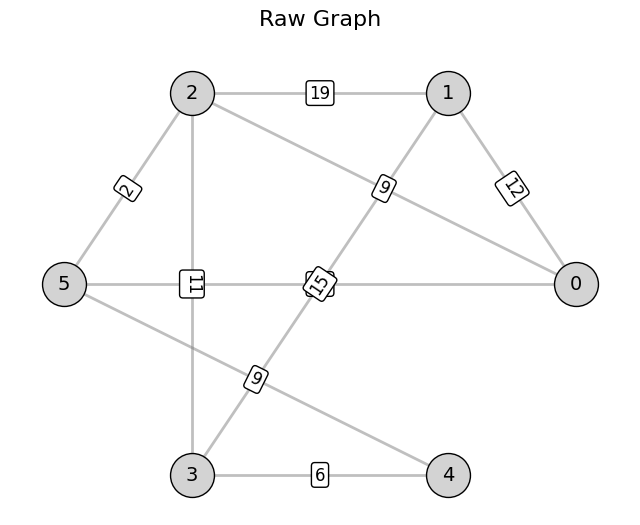

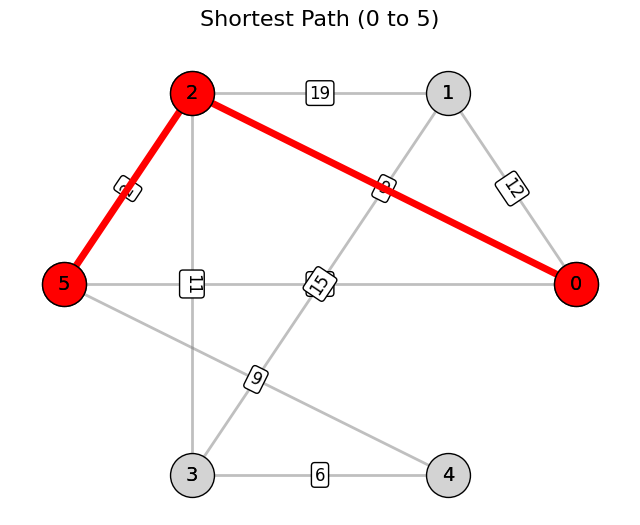

In [ ]:
# --- Cell 2: A* Algorithm & Plotting ---

def heuristic(u, v, coords):
    x1, y1 = coords[u]
    x2, y2 = coords[v]
    return abs(x1 - x2) + abs(y1 - y2)

def get_min_f_score(f_score, visited, V):
    minimum = float('inf')
    min_index = -1
    
    for v in range(V):
        if f_score[v] < minimum and not visited[v]:
            minimum = f_score[v]
            min_index = v
            
    return min_index

def a_star(graph, start, goal, coords):
    V = len(graph)

    g_score = [float('inf')] * V
    g_score[start] = 0
    
    f_score = [float('inf')] * V
    f_score[start] = heuristic(start, goal, coords)
    
    visited = [False] * V
    previous = [-1] * V

    for _ in range(V):
        u = get_min_f_score(f_score, visited, V)
        
        if u == goal or u == -1:
            break
        visited[u] = True

        for v in range(V):
            edge_weight = graph[u][v]
            
            if edge_weight > 0 and not visited[v]:
                tentative_g = g_score[u] + edge_weight
                
                if tentative_g < g_score[v]:
                    previous[v] = u
                    g_score[v] = tentative_g
                    f_score[v] = tentative_g + heuristic(v, goal, coords)

    return g_score, previous

if __name__ == "__main__":
    graph = [
        [0, 12, 9, 0, 0, 14],
        [12, 0, 19, 15, 0, 0],
        [9, 19, 0, 11, 0, 2],
        [0, 15, 11, 0, 6, 0],
        [0, 0, 0, 6, 0, 9],
        [14, 0, 2, 0, 9, 0]
    ]

    coords = [
        (0, 0),   # Node 0
        (1, 2),   # Node 1
        (2, 1),   # Node 2
        (3, 3),   # Node 3
        (4, 2),   # Node 4
        (5, 1)    # Node 5
    ]

    start = int(input("Enter the start vertex (0-5): "))
    goal = int(input("Enter the goal vertex (0-5): "))

    # 1. Run A* Algorithm
    g_score, previous = a_star(graph, start, goal, coords)
    
    # 2. Use the path function from Cell 1
    path = get_shortest_path(previous, start, goal)
    
    # 3. Print Console Results
    if path:
        print("\nPath found:", " -> ".join(map(str, path)))
        print("Total Cost:", g_score[goal])
    else:
        print("\nNo path exists.")
        
    # 4. Use the plotting function from Cell 1
    plot_graphs(graph, path, start, goal)